# 01 · Análisis exploratorio y preparación de datos (E-01 y E-02)

**Proyecto:** Detección de URLs de phishing con Machine Learning y Deep Learning
**Dataset:** PhiUSIIL Phishing URL Dataset (UCI, id 967), Prasad y Chandra, *Computers & Security*, 2024.

Objetivos de este notebook:

1. Obtener el dataset y revisar su calidad (nulos, duplicados, tipos).
2. Entender la variable objetivo y el balance de clases.
3. Medir qué tan bien separa las clases cada variable por sí sola.
4. **Detectar atajos** (*shortcuts*): variables o patrones que separan las clases por cómo se construyó el dataset y no por lo que hace phishing a una URL.
5. Crear una división train / val / test **agrupada por dominio** y guardarla para los notebooks siguientes.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

# Permite importar el módulo src/ desde la carpeta notebooks/
RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))

from src import datos

DIR_FIG = RAIZ / "reports" / "figures"
DIR_FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
COLORES = {"Legítima": "#4C72B0", "Phishing": "#DD5555"}
pd.set_option("display.max_columns", 60)

def guardar(fig, nombre):
    # Guarda cada figura en reports/figures para usarla en el informe IEEE
    fig.savefig(DIR_FIG / f"{nombre}.png", dpi=200, bbox_inches="tight")

## 1. Carga de datos (E-01)

`datos.cargar_datos()` lee `data/PhiUSIIL_Phishing_URL_Dataset.csv`; si no existe, lo descarga desde UCI con `ucimlrepo` y lo guarda.

Primero cargamos **sin** eliminar duplicados para poder contarlos.

In [2]:
df_original = datos.cargar_datos(eliminar_duplicados=False)
print(f"Filas: {df_original.shape[0]:,}  |  Columnas: {df_original.shape[1]}")
df_original.head(3)

Filas: 235,795  |  Columnas: 57


,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label,es_phishing,dominio_base
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1,0,southbankmosaics.com
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1,0,uni-mainz.de
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1,0,voicefmradio.co.uk


## 2. Vista general: tipos, nulos y duplicados

In [3]:
print("Tipos de columnas:")
print(df_original.dtypes.astype(str).value_counts().to_string())
print(f"\nValores nulos en total: {df_original.isna().sum().sum()}")

dup = df_original[df_original.URL.duplicated(keep=False)]
etiquetas_por_url = dup.groupby("URL").label.nunique()
print(f"URLs repetidas: {df_original.URL.duplicated().sum()} "
      f"(con etiquetas contradictorias: {(etiquetas_por_url > 1).sum()})")

Tipos de columnas:
int64      42
float64    10
str         5

Valores nulos en total: 0
URLs repetidas: 425 (con etiquetas contradictorias: 0)


No hay nulos. Hay URLs repetidas, pero todas con la misma etiqueta, así que simplemente dejamos una copia de cada una. Desde aquí trabajamos con el dataset limpio.

In [4]:
df = datos.cargar_datos()  # elimina URLs duplicadas
print(f"Filas tras eliminar duplicados: {len(df):,}")

Filas tras eliminar duplicados: 235,370


## 3. Variable objetivo y balance de clases

⚠️ **Ojo:** en el dataset original `label = 1` es **legítima** y `label = 0` es **phishing**. Para no confundirnos al leer el recall o la matriz de confusión, creamos `es_phishing` (1 = phishing). La clase positiva de todo el proyecto es **phishing**.

es_phishing          0       1
label original                
0                    0  100520
1               134850       0


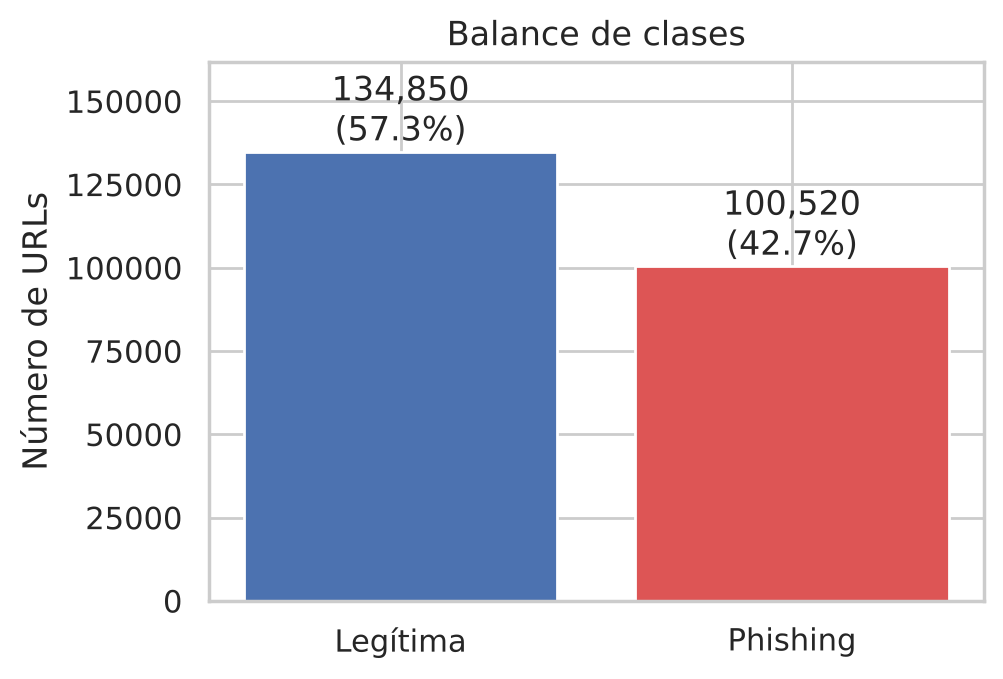

In [5]:
print(pd.crosstab(df.label, df.es_phishing, rownames=["label original"], colnames=["es_phishing"]))

df["clase"] = df.es_phishing.map({0: "Legítima", 1: "Phishing"})
conteo = df.clase.value_counts()

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(conteo.index, conteo.values, color=[COLORES[c] for c in conteo.index])
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom")
ax.set_ylabel("Número de URLs"); ax.set_title("Balance de clases")
ax.set_ylim(0, conteo.max() * 1.2)
guardar(fig, "01_balance_clases"); plt.show()

Las clases están **moderadamente desbalanceadas** (~57 % legítimas / ~43 % phishing). No es un desbalance severo, pero igual reportaremos precision, recall y F1 de la clase phishing además del accuracy.

## 4. Grupos de variables

Las variables numéricas se pueden separar según **de dónde salen**. Esto importa porque determina qué necesita el modelo en la práctica:

| Grupo | Qué requiere | Nº |
|---|---|---|
| `COLS_URL` | solo el texto de la URL | 21 |
| `COLS_SOSPECHOSAS` | comparar con una lista de URLs legítimas (`URLSimilarityIndex`) | 1 |
| `COLS_PAGINA` | descargar y analizar el HTML de la página | 28 |
| `COLS_TEXTO` | columnas de texto (URL, dominio, TLD, título) | 4 |

In [6]:
for nombre in ["COLS_URL", "COLS_SOSPECHOSAS", "COLS_PAGINA", "COLS_TEXTO"]:
    print(f"{nombre:17s}: {len(getattr(datos, nombre))} columnas")

numericas = datos.COLS_URL + datos.COLS_SOSPECHOSAS + datos.COLS_PAGINA
faltan = set(df.select_dtypes("number").columns) - set(numericas) - {"label", "es_phishing"}
print("Columnas numéricas sin grupo:", faltan or "ninguna")

COLS_URL         : 21 columnas
COLS_SOSPECHOSAS : 1 columnas
COLS_PAGINA      : 28 columnas
COLS_TEXTO       : 4 columnas
Columnas numéricas sin grupo: ninguna


## 5. ¿Qué tan bien separa cada variable por sí sola?

Para cada variable numérica calculamos el **AUC univariado**: el AUC-ROC que se obtendría usando solo esa variable como puntaje. 0.5 = no sirve, 1.0 = separa perfecto. (Usamos `max(AUC, 1 − AUC)` porque algunas variables separan "al revés".)

In [7]:
def auc_univariado(serie, y):
    auc = roc_auc_score(y, serie)
    return max(auc, 1 - auc)

def grupo_de(col):
    if col in datos.COLS_SOSPECHOSAS: return "Sospechosa"
    if col in datos.COLS_URL: return "URL"
    return "Página (HTML)"

aucs = (pd.DataFrame({"variable": numericas})
        .assign(auc=lambda d: [auc_univariado(df[c], df.es_phishing) for c in d.variable],
                grupo=lambda d: d.variable.map(grupo_de))
        .sort_values("auc", ascending=False)
        .reset_index(drop=True))
aucs.head(15)

,variable,auc,grupo
0,URLSimilarityIndex,0.996090,Sospechosa
1,LineOfCode,0.990283,Página (HTML)
2,NoOfExternalRef,0.988033,Página (HTML)
3,NoOfImage,0.979670,Página (HTML)
4,NoOfSelfRef,0.972457,Página (HTML)
5,NoOfJS,0.970894,Página (HTML)
6,NoOfCSS,0.957687,Página (HTML)
7,HasSocialNet,0.894737,Página (HTML)
8,HasCopyrightInfo,0.875498,Página (HTML)
9,HasDescription,0.846286,Página (HTML)


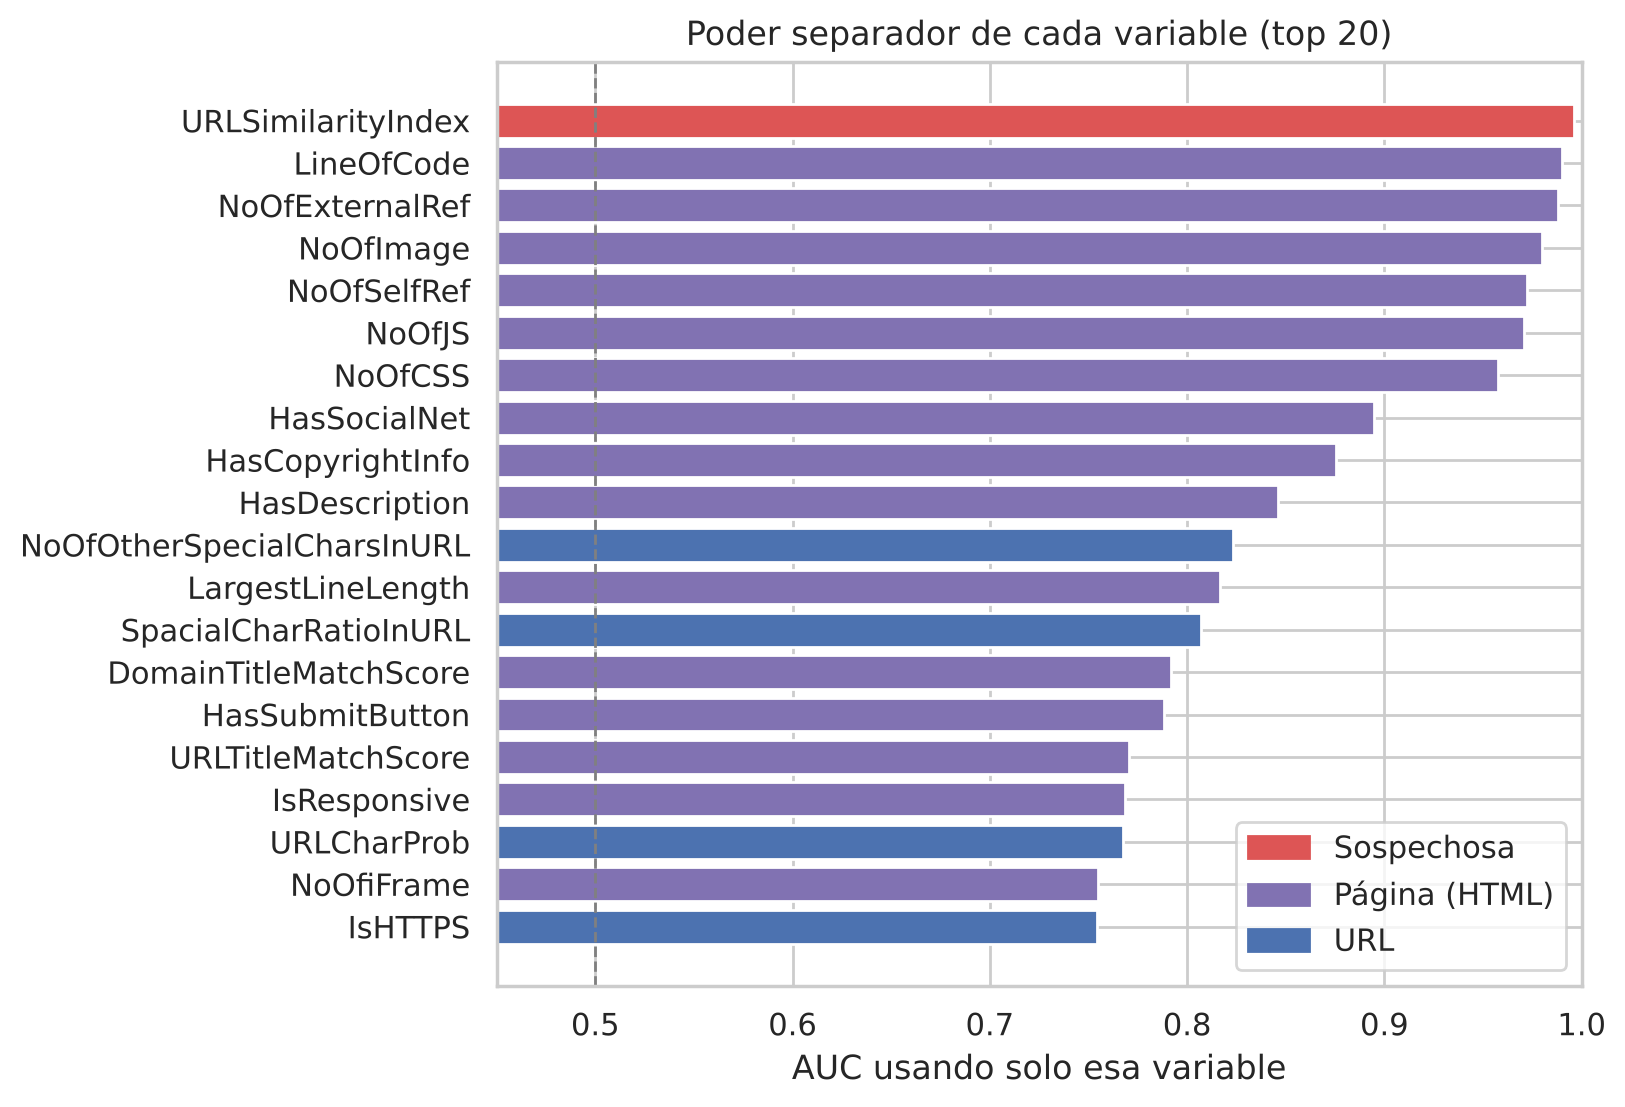

In [8]:
top = aucs.head(20).iloc[::-1]
colores_grupo = {"Sospechosa": "#DD5555", "Página (HTML)": "#8172B2", "URL": "#4C72B0"}

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.variable, top.auc, color=top.grupo.map(colores_grupo))
ax.axvline(0.5, color="gray", ls="--", lw=1)
ax.set_xlim(0.45, 1.0); ax.set_xlabel("AUC usando solo esa variable")
ax.set_title("Poder separador de cada variable (top 20)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=g) for g, c in colores_grupo.items()], loc="lower right")
guardar(fig, "02_auc_univariado"); plt.show()

**Una sola variable, `URLSimilarityIndex`, logra un AUC ≈ 0.996.** Varias variables de la página (líneas de código, referencias externas, imágenes) también superan 0.97. Que una variable sola separe casi perfecto es una alerta: hay que entender por qué antes de entrenar modelos.

## 6. Los atajos del dataset

Revisamos tres patrones:

1. El valor de `URLSimilarityIndex` en cada clase.
2. Cómo **empieza** la URL (`http://`, `https://`, con o sin `www.`).
3. Si la URL tiene **ruta** (algo después del dominio, como `/login.php`).

In [9]:
print("URLSimilarityIndex por clase:")
print(df.groupby("clase").URLSimilarityIndex.describe()[["mean", "min", "50%", "max"]].round(1))

es_100 = df.URLSimilarityIndex == 100
print(f"\nLegítimas con URLSimilarityIndex = 100: {es_100[df.es_phishing == 0].mean():.1%}")
print(f"Phishing  con URLSimilarityIndex = 100: {es_100[df.es_phishing == 1].mean():.1%}")

URLSimilarityIndex por clase:
           mean    min    50%    max
clase                               
Legítima  100.0  100.0  100.0  100.0
Phishing   49.7    0.2   51.5  100.0

Legítimas con URLSimilarityIndex = 100: 100.0%
Phishing  con URLSimilarityIndex = 100: 0.8%


In [10]:
prefijo = df.URL.str.extract(r"^(https?://(?:www\.)?)")[0].fillna("otro").rename("Prefijo")
resto = df.URL.str.replace(r"^https?://(www\.)?", "", regex=True)
tiene_ruta = resto.str.contains("/")

print("Prefijo de la URL (% de cada clase):")
print((pd.crosstab(prefijo, df.clase, normalize="columns") * 100).round(1))
print("\n¿La URL tiene ruta después del dominio? (% de cada clase):")
print((pd.crosstab(tiene_ruta.map({True: "Sí", False: "No"}).rename("Tiene ruta"), df.clase, normalize="columns") * 100).round(1))
print("\nIsHTTPS (% de cada clase):")
print((pd.crosstab(df.IsHTTPS, df.clase, normalize="columns") * 100).round(1))

Prefijo de la URL (% de cada clase):
clase         Legítima  Phishing
Prefijo                         
http://            0.0      12.3
http://www.        0.0      39.1
https://           0.0      46.2
https://www.     100.0       2.4

¿La URL tiene ruta después del dominio? (% de cada clase):
clase       Legítima  Phishing
Tiene ruta                    
No             100.0      40.3
Sí               0.0      59.7

IsHTTPS (% de cada clase):
clase    Legítima  Phishing
IsHTTPS                    
0             0.0      50.9
1           100.0      49.1


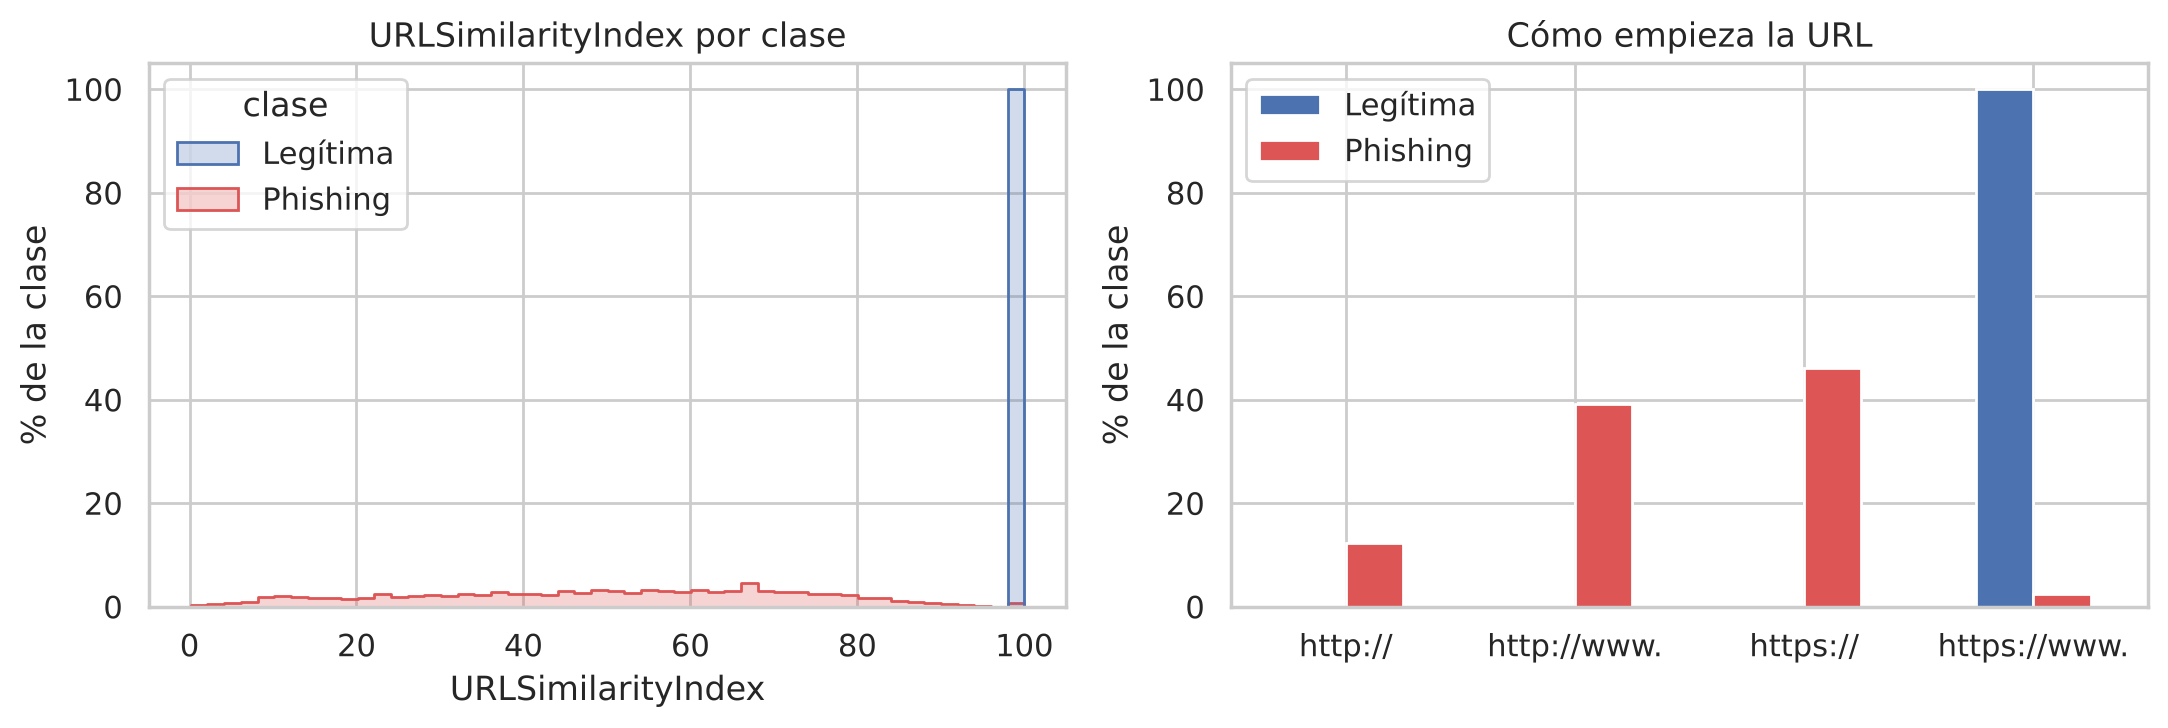

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

sns.histplot(data=df, x="URLSimilarityIndex", hue="clase", bins=50, palette=COLORES,
             element="step", stat="percent", common_norm=False, ax=axes[0])
axes[0].set_title("URLSimilarityIndex por clase")
axes[0].set_ylabel("% de la clase")

tabla = pd.crosstab(prefijo, df.clase, normalize="columns") * 100
tabla = tabla.loc[["http://", "http://www.", "https://", "https://www."]]
tabla.plot.bar(ax=axes[1], color=[COLORES[c] for c in tabla.columns], rot=0)
axes[1].set_title("Cómo empieza la URL"); axes[1].set_ylabel("% de la clase"); axes[1].set_xlabel("")
axes[1].legend(title="")
fig.tight_layout()
guardar(fig, "03_atajos"); plt.show()

**Hallazgo clave del análisis exploratorio:**

- **Todas** las URLs legítimas tienen `URLSimilarityIndex = 100`; menos del 1 % de las de phishing lo tienen.
- **Todas** las URLs legítimas empiezan con `https://www.`; solo un ~2 % de las de phishing.
- **Ninguna** URL legítima tiene ruta (son solo la página de inicio del dominio); ~60 % de las de phishing sí.

Esto se explica por cómo se construyó el dataset: las legítimas provienen de listas de dominios populares, escritas siempre como `https://www.dominio`, mientras que las de phishing son URLs reales completas. Un modelo puede llegar a ~100 % aprendiendo solo *"¿empieza con https://www. y no tiene ruta?"*, lo que **no funcionaría en el mundo real** (por ejemplo, `https://www.google.com/maps` es legítima y tiene ruta).

Consecuencia para el proyecto: además de los resultados "tal cual", evaluaremos los modelos **sin estos atajos**, para medir lo que realmente aprenden.

## 7. Distribución de otras variables importantes

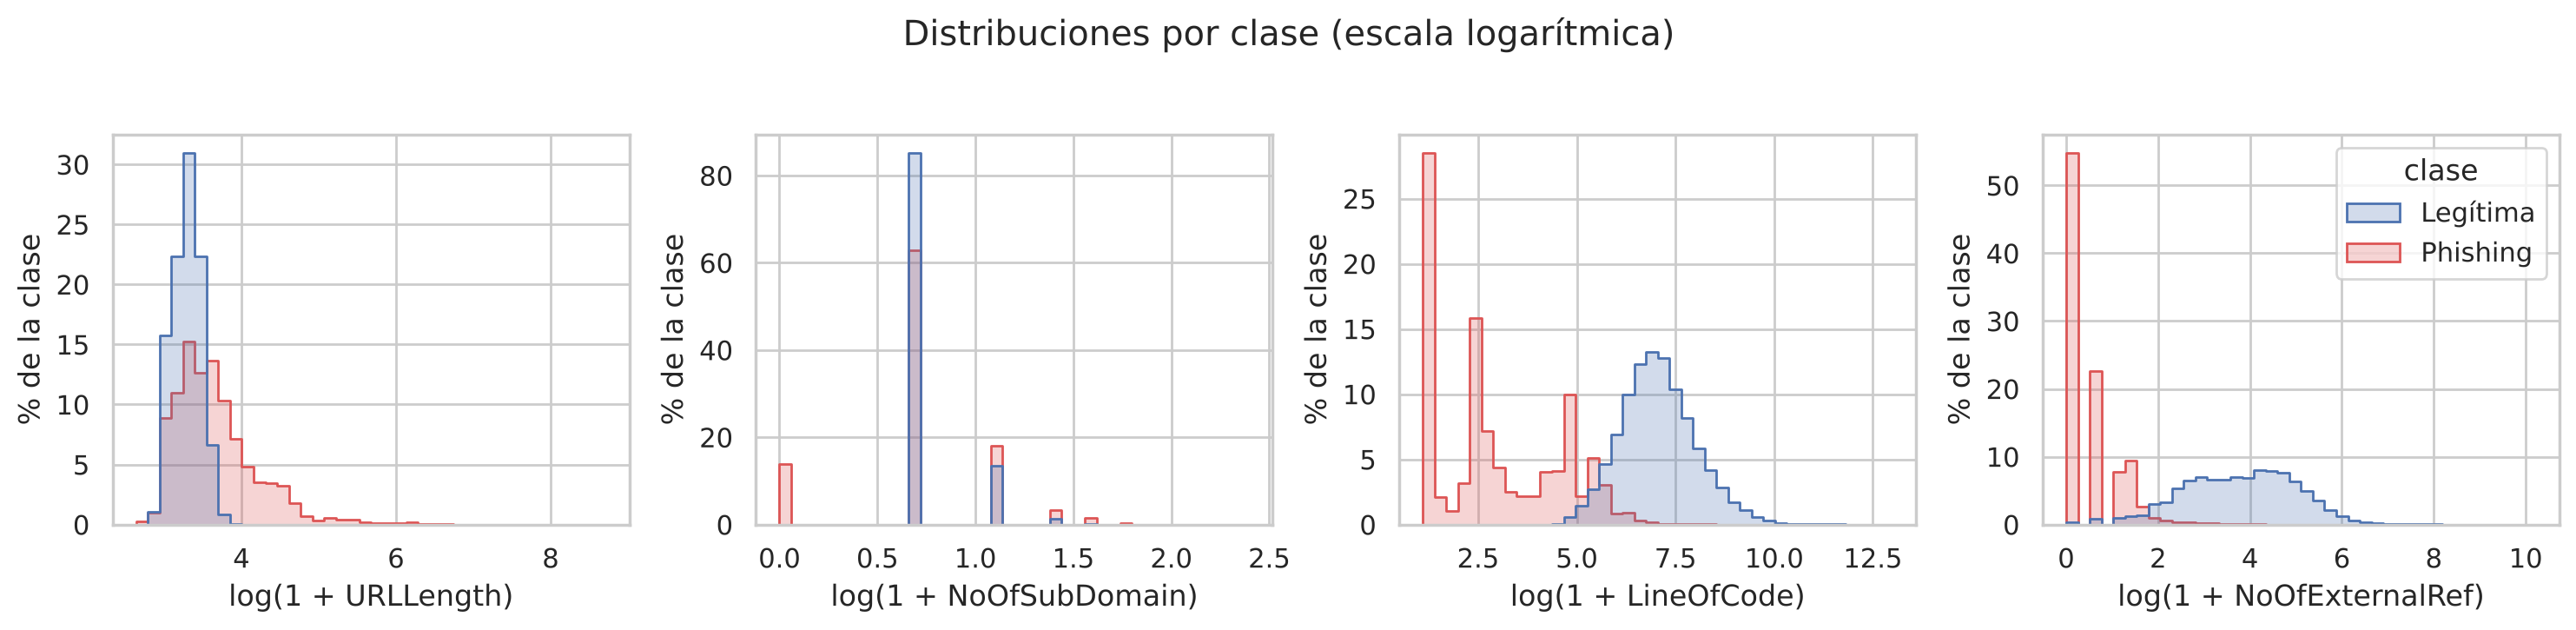

          URLLength  NoOfSubDomain  LineOfCode  NoOfExternalRef
clase                                                          
Legítima       26.0            1.0      1105.0             46.0
Phishing       34.0            1.0        12.0              0.0


In [12]:
variables = ["URLLength", "NoOfSubDomain", "LineOfCode", "NoOfExternalRef"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, var in zip(axes, variables):
    # log1p comprime las colas largas (URLs de miles de caracteres, páginas enormes)
    sns.histplot(data=df, x=np.log1p(df[var]), hue="clase", bins=40, palette=COLORES,
                 element="step", stat="percent", common_norm=False, ax=ax, legend=(var == variables[-1]))
    ax.set_xlabel(f"log(1 + {var})"); ax.set_ylabel("% de la clase")
fig.suptitle("Distribuciones por clase (escala logarítmica)", y=1.03)
fig.tight_layout()
guardar(fig, "04_distribuciones"); plt.show()

print(df.groupby("clase")[variables].median())

- Las URLs de phishing son más largas y variables (tienen rutas, parámetros y subdominios).
- Las páginas de phishing tienen **mucho menos código y menos enlaces externos**: suelen ser páginas simples que imitan un formulario de login, o ya fueron dadas de baja cuando se recolectaron. Esto también puede ser en parte un efecto de la recolección y se debe mencionar como limitación.

## 8. Correlaciones entre las variables de la URL

Variables muy correlacionadas entre sí aportan información repetida. No afecta mucho a los árboles, pero sí a la interpretación de la regresión logística.

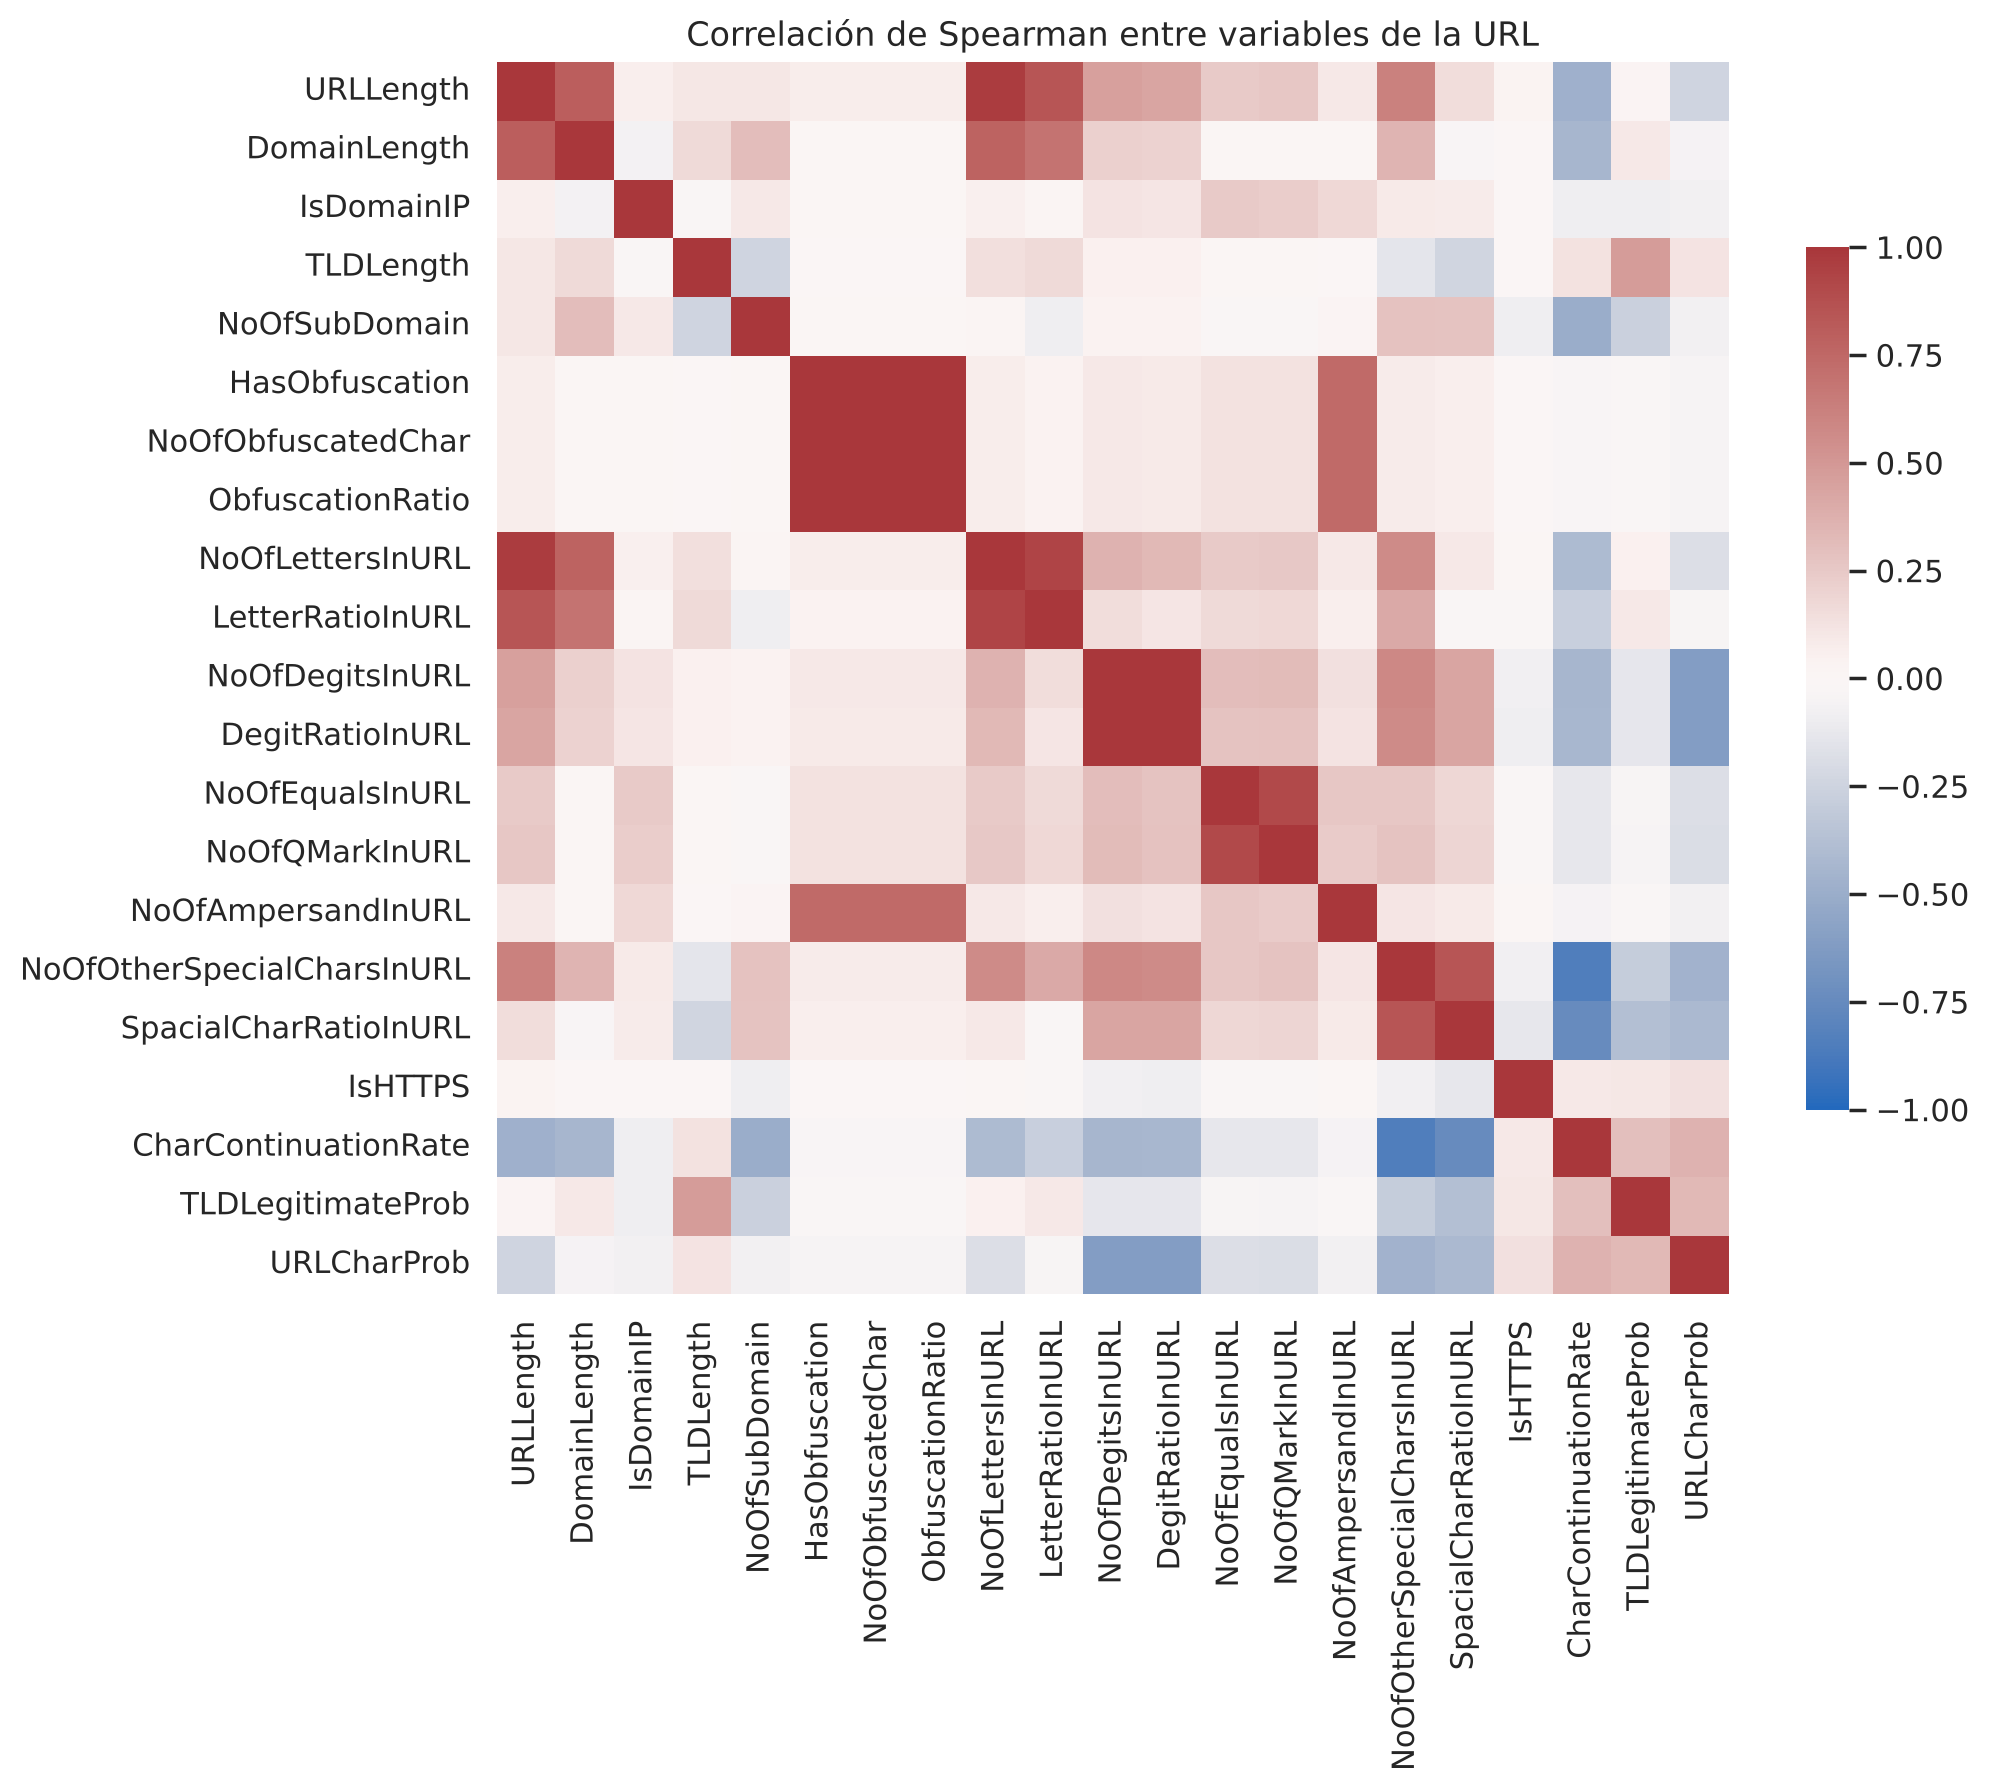

,level_0,level_1,rho
133,NoOfObfuscatedChar,ObfuscationRatio,1.000000
111,HasObfuscation,NoOfObfuscatedChar,0.999999
112,HasObfuscation,ObfuscationRatio,0.999999
221,NoOfDegitsInURL,DegitRatioInURL,0.996759
8,URLLength,NoOfLettersInURL,0.972091
177,NoOfLettersInURL,LetterRatioInURL,0.930888
265,NoOfEqualsInURL,NoOfQMarkInURL,0.909805
331,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,0.847491


In [13]:
corr = df[datos.COLS_URL].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlación de Spearman entre variables de la URL")
guardar(fig, "05_correlaciones_url"); plt.show()

pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("rho").reset_index())
pares["abs"] = pares.rho.abs()
pares.sort_values("abs", ascending=False).head(8).drop(columns="abs")

## 9. Dominios repetidos y división train / val / test (E-02)

Muchas URLs de phishing comparten dominio (una misma campaña usa varias rutas en el mismo sitio). Si dividimos al azar fila por fila, el modelo podría ver un dominio en entrenamiento y "reconocerlo" en test, inflando las métricas.

Por eso dividimos **agrupando por dominio**: todas las URLs de un dominio quedan en el mismo conjunto. Proporciones: 70 % train, 15 % validación, 15 % test.

- **train**: entrenar los modelos.
- **val**: comparar modelos y ajustar hiperparámetros.
- **test**: se usa **una sola vez**, al final, para reportar los resultados del informe.

In [14]:
urls_por_dominio = df.dominio_base.value_counts()
print(f"Dominios distintos: {urls_por_dominio.size:,}")
print(f"Dominios con más de una URL: {(urls_por_dominio > 1).sum():,}")
print("\nDominios con más URLs:")
print(urls_por_dominio.head(8).to_string())

Dominios distintos: 219,103
Dominios con más de una URL: 5,669

Dominios con más URLs:
dominio_base
ipfs.io                         1192
docs.google.com                  526
mail.deliverylifesupport.com     370
cloudflare-ipfs.com              360
storageapi.fleek.co              318
gateway.pinata.cloud             275
gateway.ipfs.io                  249
ipfs.litnet.work                 223


In [15]:
division = datos.crear_division(df)
datos.guardar_division(df, division)
df["conjunto"] = division

resumen = (df.groupby("conjunto")
             .agg(urls=("URL", "size"), dominios=("dominio_base", "nunique"),
                  pct_phishing=("es_phishing", "mean"))
             .loc[["train", "val", "test"]])
resumen["pct_del_total"] = resumen.urls / len(df)
display(resumen.style.format({"urls": "{:,}", "dominios": "{:,}",
                              "pct_phishing": "{:.1%}", "pct_del_total": "{:.1%}"}))

# Verificación: ningún dominio aparece en más de un conjunto
conjuntos_por_dominio = df.groupby("dominio_base").conjunto.nunique()
assert (conjuntos_por_dominio == 1).all(), "Hay dominios repartidos entre conjuntos"
print("✔ Ningún dominio está en más de un conjunto. División guardada en data/division.csv")

,urls,dominios,pct_phishing,pct_del_total
conjunto,,,,
train,"164,918","153,371",42.8%,70.1%
val,"35,206","32,866",42.4%,15.0%
test,"35,246","32,866",42.4%,15.0%


✔ Ningún dominio está en más de un conjunto. División guardada en data/division.csv


## 10. Experimento rápido: ¿cuánto depende un modelo de los atajos?

Antes de la etapa de modelos (E-04 y E-05) hacemos una prueba diagnóstica con un modelo muy simple: **TF-IDF de n-gramas de caracteres + regresión logística**, entrenado en *train* y evaluado en *val*. Le mostramos tres versiones del texto:

1. **URL original**: `https://www.uni-mainz.de`
2. **URL normalizada**: sin `http(s)://`, sin `www.` y sin `/` final → `uni-mainz.de/login.php`
3. **Solo el dominio**: `uni-mainz.de` (sin ruta: elimina también el atajo "tiene ruta")

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

tr, va = df[df.conjunto == "train"], df[df.conjunto == "val"]
versiones = {
    "URL original": lambda d: d.URL,
    "URL normalizada": lambda d: datos.normalizar_url(d.URL),
    "Solo dominio": lambda d: d.dominio_base,
}

filas = []
for nombre, texto in versiones.items():
    modelo = make_pipeline(
        TfidfVectorizer(analyzer="char", ngram_range=(2, 4), max_features=50_000, sublinear_tf=True),
        LogisticRegression(max_iter=1000, C=4),
    )
    modelo.fit(texto(tr), tr.es_phishing)
    pred = modelo.predict(texto(va))
    filas.append({"Texto de entrada": nombre,
                  "Accuracy": accuracy_score(va.es_phishing, pred),
                  "Precision (phishing)": precision_score(va.es_phishing, pred),
                  "Recall (phishing)": recall_score(va.es_phishing, pred),
                  "F1 (phishing)": f1_score(va.es_phishing, pred)})

res_atajos = pd.DataFrame(filas).set_index("Texto de entrada")
display(res_atajos.style.format("{:.3f}"))

,Accuracy,Precision (phishing),Recall (phishing),F1 (phishing)
Texto de entrada,,,,
URL original,0.997,1.000,0.994,0.997
URL normalizada,0.901,0.945,0.815,0.875
Solo dominio,0.871,0.916,0.766,0.834


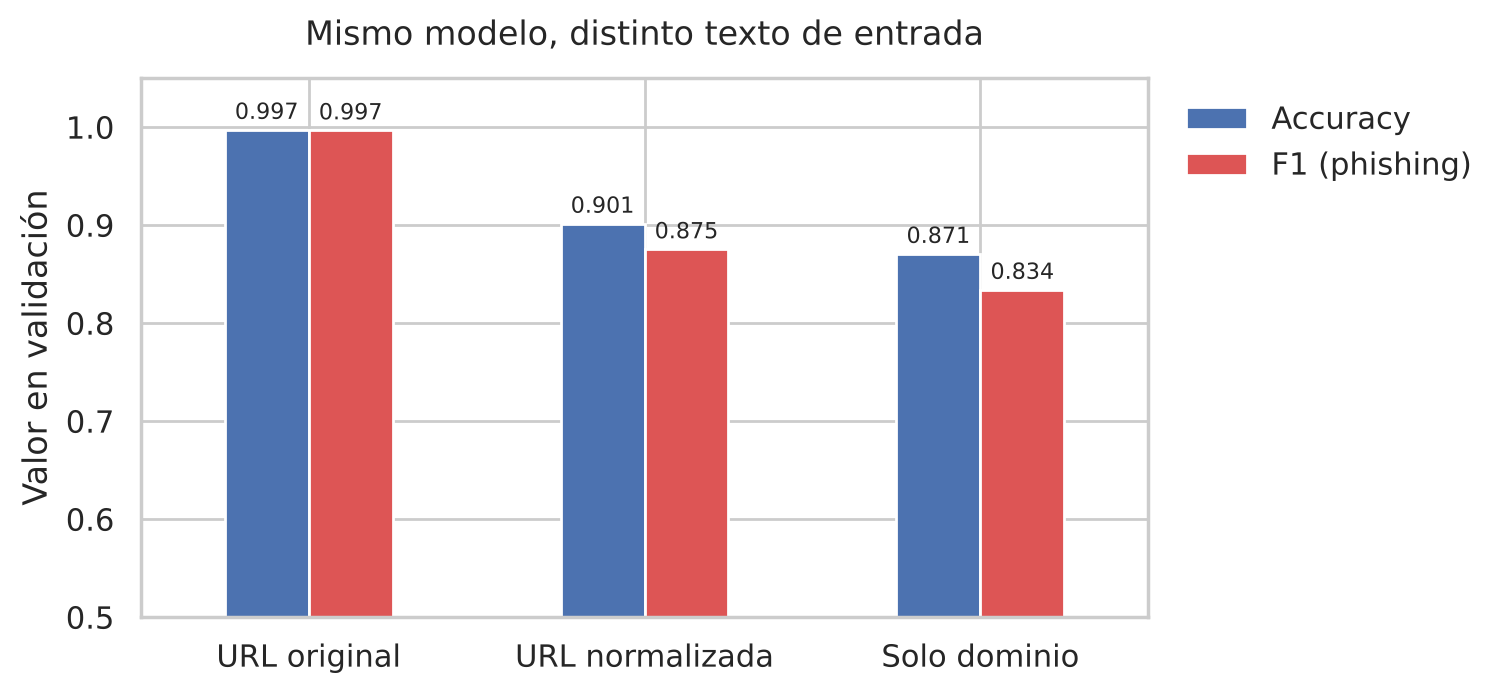

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
res_atajos[["Accuracy", "F1 (phishing)"]].plot.bar(ax=ax, rot=0, color=["#4C72B0", "#DD5555"])
ax.set_ylim(0.5, 1.05); ax.set_ylabel("Valor en validación"); ax.set_xlabel("")
ax.set_title("Mismo modelo, distinto texto de entrada", pad=12)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.3f", fontsize=8, padding=2)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
guardar(fig, "06_experimento_atajos"); plt.show()

Al quitar el esquema, el `www.` y la ruta, el **mismo modelo** pasa de ~99,7 % a ~87-90 % de accuracy, y el recall de phishing cae de ~99 % a ~77-82 %. Esa diferencia es lo que aportaban los atajos; lo que queda es lo que el modelo aprende de los caracteres del dominio (palabras como *login*, *secure*, *verify*, TLDs como `.xyz` o `.gq`, dominios con números, etc.).

## 11. Conclusiones del análisis y decisiones para las siguientes etapas

**Calidad de datos.** 235.795 URLs, sin nulos; se eliminaron 425 URLs duplicadas (sin etiquetas contradictorias). Se trabaja con `es_phishing` (1 = phishing) para evitar la confusión de la etiqueta original.

**Atajos detectados.** `URLSimilarityIndex = 100`, el prefijo `https://www.` y la ausencia de ruta identifican a casi todas las legítimas. Además, `IsHTTPS` vale 1 en todas las legítimas. Son artefactos de cómo se armó el dataset.

**División.** Train/val/test 70/15/15 agrupada por dominio, guardada en `data/division.csv` y reutilizada por todos los notebooks.

**Decisiones para E-04 / E-05:**

1. **Enfoque A, variables tabulares** (regresión logística, Random Forest, XGBoost, MLP) en tres escenarios:
   - A1: todas las variables (comparable con la literatura; se espera ~100 %).
   - A2: sin `URLSimilarityIndex`.
   - A3: solo variables de la URL (`COLS_URL`), sin las que requieren descargar la página.
2. **Enfoque B, solo el texto** (TF-IDF + regresión logística como línea base, CNN de caracteres y LSTM/BiGRU en Keras), entrenados con la **URL normalizada** o el **dominio**, para que no aprendan el atajo del prefijo.
3. **Métricas:** precision, recall y F1 de la clase phishing, ROC-AUC y matriz de confusión. El test se usa solo al final.
4. **Limitación a declarar en el informe:** las URLs legítimas son solo páginas de inicio de dominios populares, así que ningún resultado sobre este dataset garantiza el mismo desempeño en URLs reales. Trabajo futuro: validar con otra fuente (p. ej., PhishTank y URLs legítimas con ruta).